# 06 — Systematic Empirical Comparison Against Established Baselines
**Course:** 22AIE401 — Reinforcement Learning  
**Project:** Reinforcement Learning for Drug-Likeness Optimization of Small Molecules  
**Dataset:** ZINC-250K Expanded Final Test Benchmark (500 Molecules across 4 QED Tiers)  

---

## Expanded Final Test Benchmark — 500 Unseen Molecules (2,000 Total Trajectories)
In this notebook, we systematically evaluate and compare the **Proposed Adaptive PPO Agent** against three benchmark baselines across the expanded 500-molecule test benchmark (2,000 total trajectories):
1. **Random Valid Edits Baseline:** Samples uniformly from chemically valid editing actions; establishes an unbiased lower-bound exploration baseline.
2. **Greedy Hill-Climbing Baseline (1-step Lookahead Oracle):** Evaluates all possible valid chemical modifications at each step and greedily selects the single edit yielding the highest immediate QED improvement.
3. **PPO Baseline (Unshaped):** A standard PPO agent trained with an unshaped reward function ($R = \Delta \text{QED} - \text{penalty}$).
4. **PPO Proposed (Adaptive):** Incorporates **Headroom- and Constraint-Slack Adaptive Reward Shaping** to balance drug-likeness gains against structural similarity and synthetic accessibility.

### Target Dataset Configuration (80:10:10 Ratio):
- **Training:** 4,000 molecules (80%)
- **Validation:** 500 molecules (10%)
- **Final Testing:** 500 molecules (10%)
- **Zero Cross-Split Scaffold Overlap:** Guaranteed via Bemis-Murcko scaffold clustering.

### Formal Benchmark Success Criterion:
$$\text{Success} \iff \Delta\text{QED} \ge 0.10 \quad \text{AND} \quad \text{Tanimoto}(M_T, M_0) \ge 0.40 \quad \text{AND} \quad \text{SAS}_T \le \max(\text{SAS}_0, 4.5)$$


In [1]:
import os, sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

benchmark_path = os.path.join(WORKSPACE_DIR, 'data', 'splits', 'test_benchmark_molecules.csv')
bench_df = pd.read_csv(benchmark_path)
overlap_path = os.path.join(WORKSPACE_DIR, 'data', 'splits', 'scaffold_overlap_report.csv')
overlap_df = pd.read_csv(overlap_path)
split_info_path = os.path.join(WORKSPACE_DIR, 'data', 'splits', 'split_info.json')
with open(split_info_path, 'r') as fp:
    split_info = json.load(fp)

print(f"Final Test Benchmark Size: {len(bench_df)} molecules (2,000 total trajectories across 4 methods)")
print(f"Dataset Split Configuration: {split_info['train_molecules_count']} Train | {split_info['val_molecules_count']} Val | {split_info['test_molecules_count']} Test")
print("\n--- Scaffold Overlap Verification ---")
print(overlap_df.to_string(index=False))

print("\n--- Distribution across Starting-QED Groups ---")
qed_dist = bench_df['qed_group'].value_counts()
for group, count in qed_dist.items():
    print(f"  {group:20s}: {count:3d} molecules")

print("\nBenchmark Summary Statistics (N=500):")
print(bench_df[['qed', 'sas', 'molecular_weight', 'heavy_atom_count']].describe().round(3).to_string())

Final Test Benchmark Size: 500 molecules (2,000 total trajectories across 4 methods)
Dataset Split Configuration: 4000 Train | 500 Val | 500 Test

--- Scaffold Overlap Verification ---
              comparison  scaffold_overlap_count  smiles_overlap_count                status
     Train vs Validation                       0                     0 PASSED (Zero Leakage)
     Train vs Final Test                       0                     0 PASSED (Zero Leakage)
Validation vs Final Test                       0                     0 PASSED (Zero Leakage)

--- Distribution across Starting-QED Groups ---
  Low (<0.50)         : 125 molecules
  Medium (0.50-0.70)  : 125 molecules
  High (0.70-0.85)    : 125 molecules
  Very High (>=0.85)  : 125 molecules

Benchmark Summary Statistics (N=500):
           qed      sas  molecular_weight  heavy_atom_count
count  500.000  500.000           500.000           500.000
mean     0.678    2.998           353.314            24.678
std      0.179    0.772

## 2. Overall Performance Comparison Matrix (500 Test Molecules)
We load the compiled empirical evaluation results across all 500 held-out test molecules (2,000 evaluation trajectories).

In [2]:
summary_path = os.path.join(WORKSPACE_DIR, 'results', 'method_comparison_summary.csv')
summary_df = pd.read_csv(summary_path)

cols_to_show = [
    'method', 'mean_delta_qed', 'mean_nhg', 'success_rate',
    'mean_similarity', 'mean_delta_sas', 'validity_rate', 'mean_edits'
]

display_df = summary_df[cols_to_show].copy()
display_df['mean_delta_qed'] = display_df['mean_delta_qed'].map('{:+.4f}'.format)
display_df['mean_nhg'] = display_df['mean_nhg'].map('{:.3f}'.format)
display_df['success_rate'] = (display_df['success_rate'] * 100).map('{:.1f}%'.format)
display_df['mean_similarity'] = display_df['mean_similarity'].map('{:.3f}'.format)
display_df['mean_delta_sas'] = display_df['mean_delta_sas'].map('{:+.3f}'.format)
display_df['validity_rate'] = (display_df['validity_rate'] * 100).map('{:.1f}%'.format)
display_df['mean_edits'] = display_df['mean_edits'].map('{:.2f}'.format)

print("Comprehensive Benchmark Evaluation Matrix (N=500 Held-out Test Molecules):")
print(display_df.to_string(index=False))

Comprehensive Benchmark Evaluation Matrix (N=500 Held-out Test Molecules):
                 method mean_delta_qed mean_nhg success_rate mean_similarity mean_delta_sas validity_rate mean_edits
     Random Valid Edits        -0.4243   -2.313         2.2%           0.249         +1.971        100.0%       9.39
PPO Baseline (Unshaped)        -0.3782   -2.080         5.4%           0.271         +1.336        100.0%       9.53
PPO Proposed (Adaptive)        -0.1730   -0.928         5.0%           0.473         +0.827        100.0%       9.58
   Greedy Hill Climbing        +0.1229    0.381        65.4%           0.619         +0.502        100.0%       1.42


## 3. Comparative Visualizations across Evaluation Metrics
We generate side-by-side comparative bar charts illustrating the primary trade-offs between optimization gain ($\Delta$QED, Success Rate) and structural preservation (Tanimoto Similarity, $\Delta$SAS).

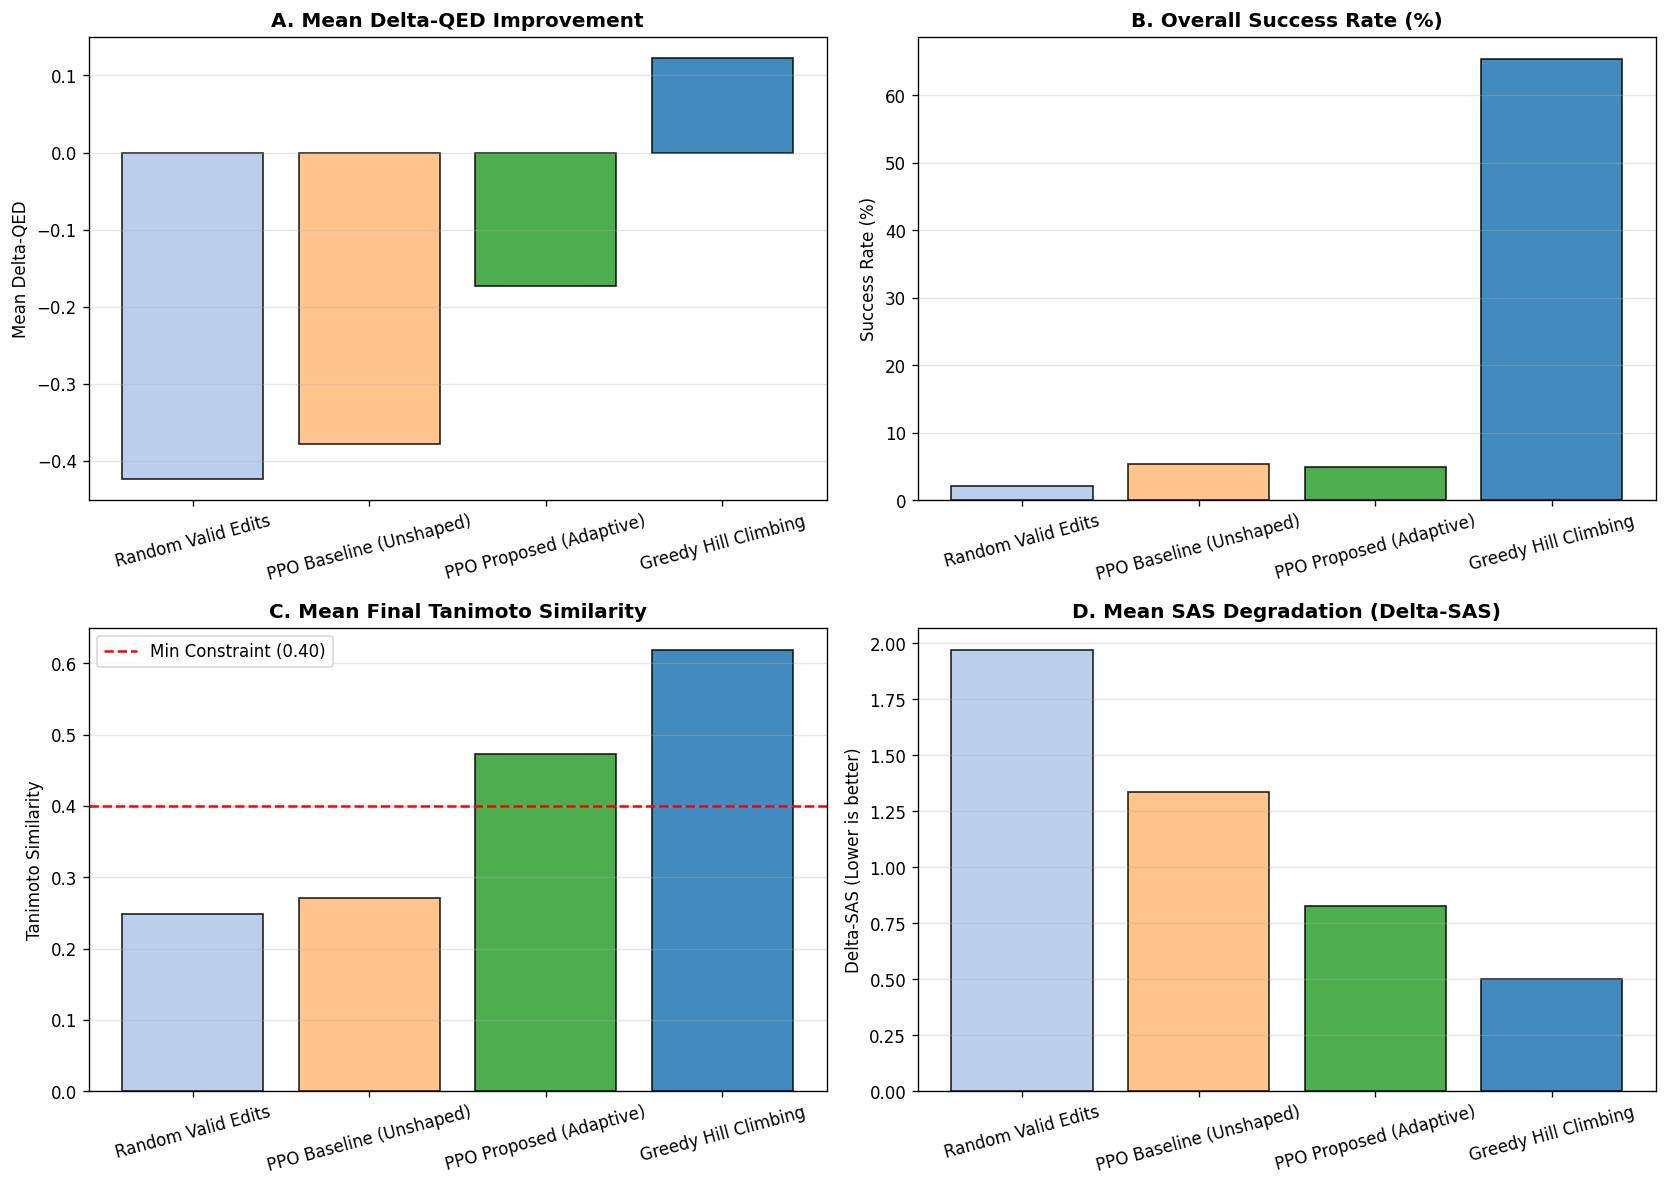

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

methods = summary_df['method']
colors = ['#aec7e8', '#ffbb78', '#2ca02c', '#1f77b4']

# 1. Delta QED
axes[0, 0].bar(methods, summary_df['mean_delta_qed'], color=colors, edgecolor='black', alpha=0.85)
axes[0, 0].set_title('A. Mean Delta-QED Improvement', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Mean Delta-QED')
axes[0, 0].grid(axis='y', alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=15)

# 2. Success Rate
axes[0, 1].bar(methods, summary_df['success_rate'] * 100, color=colors, edgecolor='black', alpha=0.85)
axes[0, 1].set_title('B. Overall Success Rate (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Success Rate (%)')
axes[0, 1].grid(axis='y', alpha=0.3)
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Tanimoto Similarity
axes[1, 0].bar(methods, summary_df['mean_similarity'], color=colors, edgecolor='black', alpha=0.85)
axes[1, 0].axhline(0.40, color='red', linestyle='--', label='Min Constraint (0.40)')
axes[1, 0].set_title('C. Mean Final Tanimoto Similarity', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Tanimoto Similarity')
axes[1, 0].grid(axis='y', alpha=0.3)
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].legend()

# 4. Delta SAS
axes[1, 1].bar(methods, summary_df['mean_delta_sas'], color=colors, edgecolor='black', alpha=0.85)
axes[1, 1].set_title('D. Mean SAS Degradation (Delta-SAS)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Delta-SAS (Lower is better)')
axes[1, 1].grid(axis='y', alpha=0.3)
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 4. QED-Stratified Performance Analysis
Optimization dynamics vary drastically depending on the starting drug-likeness of the parent molecule:
- **Low QED (<0.50):** Large available headroom; high potential for dramatic multi-step improvements.
- **Medium QED (0.50-0.70):** Moderate headroom; requires balanced substitutions.
- **High QED (0.70-0.85):** Subtle modifications; higher risk of breaking similarity constraints.
- **Very High QED (>=0.85):** Little to no headroom; policy must intelligently invoke the **STOP** action to avoid degrading an already optimized molecule.

Mean Delta-QED Stratified across Tiers:
method              Greedy Hill Climbing  PPO Baseline (Unshaped)  PPO Proposed (Adaptive)  Random Valid Edits
qed_group                                                                                                     
High (0.70-0.85)                  0.1025                  -0.4384                  -0.2175             -0.4894
Low (<0.50)                       0.2013                  -0.2186                  -0.1045             -0.2543
Medium (0.50-0.70)                0.1503                  -0.3344                  -0.1424             -0.3794
Very High (>=0.85)                0.0376                  -0.5214                  -0.2275             -0.5742

Mean Final Similarity Stratified across Tiers:
method              Greedy Hill Climbing  PPO Baseline (Unshaped)  PPO Proposed (Adaptive)  Random Valid Edits
qed_group                                                                                                     
High (0.70-0.85)        

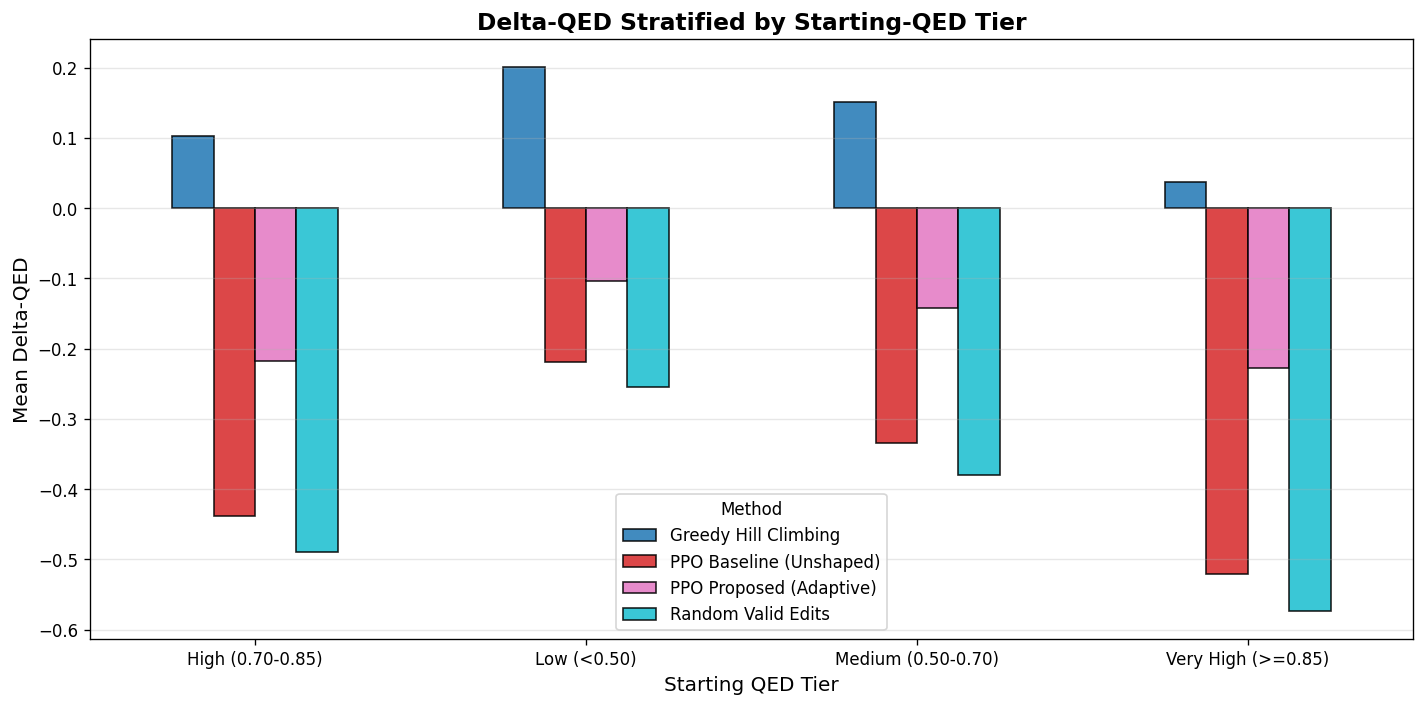

In [4]:
strat_path = os.path.join(WORKSPACE_DIR, 'results', 'qed_stratified_summary.csv')
strat_df = pd.read_csv(strat_path)

# Pivot table for Delta-QED
pivot_delta = strat_df.pivot(index='qed_group', columns='method', values='mean_delta_qed')
pivot_sim = strat_df.pivot(index='qed_group', columns='method', values='mean_similarity')

print("Mean Delta-QED Stratified across Tiers:")
print(pivot_delta.round(4).to_string())

print("\nMean Final Similarity Stratified across Tiers:")
print(pivot_sim.round(3).to_string())

# Plot stratified comparison
fig, ax = plt.subplots(figsize=(12, 6))
pivot_delta.plot(kind='bar', ax=ax, colormap='tab10', edgecolor='black', alpha=0.85)
ax.set_title('Delta-QED Stratified by Starting-QED Tier', fontsize=14, fontweight='bold')
ax.set_xlabel('Starting QED Tier', fontsize=12)
ax.set_ylabel('Mean Delta-QED', fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Method')

plt.tight_layout()
plt.show()

## 5. Qualitative Inspection of Molecular Edits
We inspect concrete molecule trajectories from `final_evaluation_results.csv` comparing the modifications made by the Greedy Oracle vs. the Proposed Adaptive PPO Agent.

In [5]:
eval_path = os.path.join(WORKSPACE_DIR, 'results', 'final_evaluation_results.csv')
eval_df = pd.read_csv(eval_path)

cols_inspect = ['method', 'initial_smiles', 'final_smiles', 'initial_qed', 'final_qed', 'delta_qed', 'similarity']
print("Representative Edited Molecules:")
for method, group in eval_df.groupby('method'):
    print(f"\n================ Method: {method} ================")
    sample = group.iloc[0]
    print(f"Initial SMILES : {sample['initial_smiles']}")
    print(f"Final SMILES   : {sample['final_smiles']}")
    print(f"QED Change     : {sample['initial_qed']:.4f} -> {sample['final_qed']:.4f} (Delta: {sample['delta_qed']:+.4f})")
    print(f"Final Sim      : {sample['similarity']:.4f} (Constraint Met: {sample['similarity'] >= 0.40})")
    print(f"Edits Taken    : {sample['num_edits']}")

Representative Edited Molecules:

================ Method: Greedy Hill Climbing ================
Initial SMILES : Cc1noc(NC(=O)CSc2nnc(-c3cccc(Cl)c3)n2-c2ccccc2C(F)(F)F)n1
Final SMILES   : CS1=NOC(NC(=O)CSc2nnc(-c3cccc(Cl)c3)n2-c2ccccc2C(F)(F)F)=N1
QED Change     : 0.3753 -> 0.5072 (Delta: +0.1320)
Final Sim      : 0.6883 (Constraint Met: True)
Edits Taken    : 1

================ Method: PPO Baseline (Unshaped) ================
Initial SMILES : Cc1noc(NC(=O)CSc2nnc(-c3cccc(Cl)c3)n2-c2ccccc2C(F)(F)F)n1
Final SMILES   : Cc1cc(-c2nnc(S(S)(S)NC(=O)Nc3nc(N)no3)n2-c2ccccc2C(F)(F)F)c(C)c(Cl)c1Cl
QED Change     : 0.3753 -> 0.1274 (Delta: -0.2479)
Final Sim      : 0.4043 (Constraint Met: True)
Edits Taken    : 10

================ Method: PPO Proposed (Adaptive) ================
Initial SMILES : Cc1noc(NC(=O)CSc2nnc(-c3cccc(Cl)c3)n2-c2ccccc2C(F)(F)F)n1
Final SMILES   : CC(C)(CO)c1noc(NC(=O)C#Sc2nnc(-c3cc(S)cc(F)n3)n2-c2ccccc2C(N)(F)F)n1
QED Change     : 0.3753 -> 0.1569 (Delta: -0.2184)
Final 